### Hxtorch single neuron testing
- the counterpart is the Leaky/LIF neuron in Roels code implementation
- here I use the same spike input trail with the same parameters to inspect just how much different the neuron behaves with same parameters and the same numerical weight
- calibration of parameters is done automatically, calibration of every single parameter to match Roels code is not recommended

- tutorial: ts_12-hxtroch_snn_intro

choices 
- weight = 55, chosen from the tutorial
- (software) w_model, model_threshold = 0.1, 0.3 (use weight ratio for BSS2)
- dt = 1e-6, tau_mem = 10e-6
- input spike every third step

reminder
- hxtorch (in mock mode) exists in two forms at once (simulation/hardware), therefore it takes two values, used to compute gradients in the numerical layer
- Software model. The notebook says every layer has a PyTorch-differentiable numerical version (forward_func). It is used for gradients and, with mock=True, to simulate the network. It works in model units, where the tutorial sets leak 0, reset 0 and threshold 
- Hardware neuron. This is the physical neuron on the chip. Its settings are in the chip’s own units (CADC values), which is why the tutorial uses 80, 80 and 125.

In [1]:
%matplotlib inline
from functools import partial
import numpy as np, torch, matplotlib.pyplot as plt
import hxtorch, hxtorch.snn as hxsnn
from hxtorch.snn.transforms.weight_transforms import linear_saturating
from _static.common.helpers import setup_hardware_client, save_nightly_calibration

setup_hardware_client()
save_nightly_calibration('spiking_calix-native.pkl') # from tutorial
hxtorch.init_hardware()

INFO  14:54:44,395  demo_helpers Connection to hxcube7fpga3chip61_1 established


#### Single hxtorch neuron on hardware
- no mock mode, entirely on chip

torch.Size([100, 1, 1]) torch.Size([100, 1, 1])
output spikes at steps: [12 19 26 33 40 47 53 59 66 72 79 85 92 98]


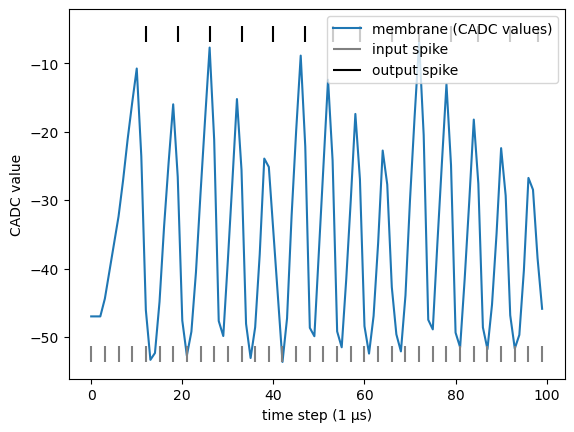

In [2]:
T = 100                                   # 100 steps of dt = 1 µs
w_hw = 55                                 # integer hardware weight (-63..63)

exp = hxsnn.Experiment(dt=1e-6)
exp.default_execution_instance.load_calib("spiking_calix-native.pkl")

syn = hxsnn.Synapse(in_features=1, out_features=1, experiment=exp)
lif = hxsnn.LIF(
    size=1, experiment=exp,
    enable_cadc_recording=True,
    enable_spike_recording=True,
    record_neuron_id=0,
    cadc_time_shift=-1)                   # copied from the tutorial

syn.weight.data.fill_(w_hw)

inputs = torch.zeros((T, 1, 1))           # (time, batch, features), as in the tutorial
inputs[::3] = 1.0                         # one input spike every third step

g = syn(hxsnn.LIFObservables(spikes=inputs))
z = lif(g)
hxsnn.run(exp, T)

trace = z.membrane_cadc.detach().numpy().reshape(-1)
spikes = z.spikes.detach().numpy().reshape(-1)
print(z.spikes.shape, z.membrane_cadc.shape)
print("output spikes at steps:", np.nonzero(spikes)[0])

plt.plot(trace, label="membrane (CADC values)")
plt.vlines(np.nonzero(inputs.numpy().reshape(-1))[0], trace.min(), trace.min() + 0.05 * np.ptp(trace),
           color="gray", label="input spike")
plt.vlines(np.nonzero(spikes)[0], trace.max(), trace.max() + 0.05 * np.ptp(trace),
           color="k", label="output spike")
plt.xlabel("time step (1 µs)"); plt.ylabel("CADC value"); plt.legend(); plt.show()

hxtorch.release_hardware()

- I do not see decay, reduce input spikes and lower the weight
- the PyNN experiments revealed that for single neuron experiments a weight lower than 53 does not lead to a spike

torch.Size([100, 1, 1]) torch.Size([100, 1, 1])
output spikes at steps: [17 30 41 52 63 74 84 96]


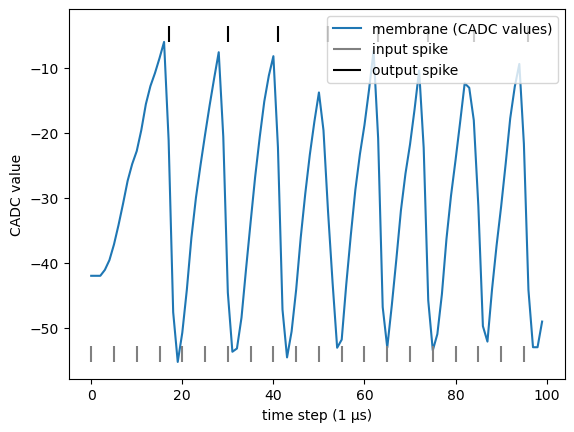

In [6]:
#hxtorch.init_hardware()
exp = hxsnn.Experiment(dt=1e-6)
exp.default_execution_instance.load_calib("spiking_calix-native.pkl")

T = 100                                   # 100 steps of dt = 1 µs
w_hw = 55  

syn1 = hxsnn.Synapse(in_features=1, out_features=1, experiment=exp)
lif1 = hxsnn.LIF(
    size=1, experiment=exp,
    enable_cadc_recording=True,
    enable_spike_recording=True,
    record_neuron_id=0,
    cadc_time_shift=-1)                   # copied from the tutorial

syn1.weight.data.fill_(w_hw)

inputs1 = torch.zeros((T, 1, 1))           # (time, batch, features), as in the tutorial
inputs1[::5] = 1.0                         # one input spike every third step

g1 = syn1(hxsnn.LIFObservables(spikes=inputs1))
z1 = lif1(g1)
hxsnn.run(exp, T)

trace1 = z1.membrane_cadc.detach().numpy().reshape(-1)
spikes1 = z1.spikes.detach().numpy().reshape(-1)
print(z1.spikes.shape, z1.membrane_cadc.shape)
print("output spikes at steps:", np.nonzero(spikes1)[0])

plt.plot(trace1, label="membrane (CADC values)")
plt.vlines(np.nonzero(inputs1.numpy().reshape(-1))[0], trace1.min(), trace1.min() + 0.05 * np.ptp(trace1),
           color="gray", label="input spike")
plt.vlines(np.nonzero(spikes1)[0], trace1.max(), trace1.max() + 0.05 * np.ptp(trace1),
           color="k", label="output spike")
plt.xlabel("time step (1 µs)"); plt.ylabel("CADC value"); plt.legend(); plt.show()

hxtorch.release_hardware()

torch.Size([100, 1, 1]) torch.Size([100, 1, 1])
output spikes at steps: [18 31 43 55 67 79 91]


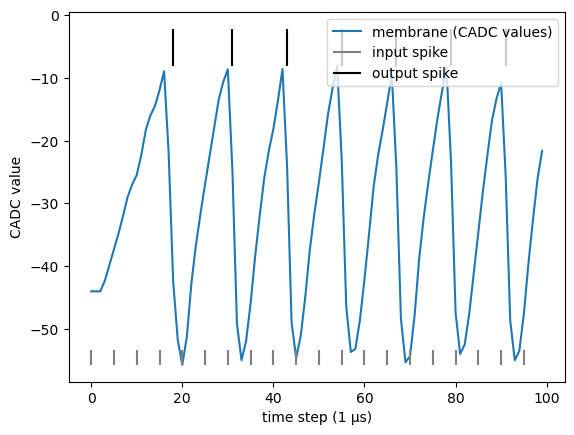

In [4]:
#hxtorch.init_hardware()
exp1 = hxsnn.Experiment(dt=1e-6)
exp1.default_execution_instance.load_calib("spiking_calix-native.pkl")

T = 100                                   # 100 steps of dt = 1 µs
w_hw = 53  

syn2 = hxsnn.Synapse(in_features=1, out_features=1, experiment=exp1)
lif2 = hxsnn.LIF(
    size=1, experiment=exp1,
    enable_cadc_recording=True,
    enable_spike_recording=True,
    record_neuron_id=0,
    cadc_time_shift=-1)                   # copied from the tutorial

syn2.weight.data.fill_(w_hw)

inputs2 = torch.zeros((T, 1, 1))           # (time, batch, features), as in the tutorial
inputs2[::5] = 1.0                         # one input spike every third step

g2 = syn2(hxsnn.LIFObservables(spikes=inputs2))
z2 = lif2(g2)
hxsnn.run(exp1, T)

trace2 = z2.membrane_cadc.detach().numpy().reshape(-1)
spikes2 = z2.spikes.detach().numpy().reshape(-1)
print(z2.spikes.shape, z2.membrane_cadc.shape)
print("output spikes at steps:", np.nonzero(spikes2)[0])

plt.plot(trace2, label="membrane (CADC values)")
plt.vlines(np.nonzero(inputs2.numpy().reshape(-1))[0], trace2.min(), trace2.min() + 0.05 * np.ptp(trace2),
           color="gray", label="input spike")
plt.vlines(np.nonzero(spikes2)[0], trace2.max(), trace1.max() + 0.05 * np.ptp(trace2),
           color="k", label="output spike")
plt.xlabel("time step (1 µs)"); plt.ylabel("CADC value"); plt.legend(); plt.show()

hxtorch.release_hardware()

- no leak present, same weight and constant spike rates but different amplitudes in the 2nd plot

#### Single hxtorch neuron with mock mode (simulation/hardware, with calibration)

In [ ]:

# model side (same ratios as the software run)
T = 100
w_model, model_threshold, model_leak, model_reset = 0.1, 0.3, 0., 0.
# BSS-2 side (tutorial defaults)
bss2_threshold, bss2_leak, bss2_reset = 125, 80, 80


# from tutorial: if model value and hardware value differ, use MixedHXModelParameter
# otherwise HXParameter as default

# tau_mem, tau_syn, refractory_time etc. are not defined, they keep their defaults
def run(inputs, weight_scale=55., trace_offset=0., trace_scale=1., n_runs=10):
    traces, spikes = [], []
    for _ in range(n_runs):
        exp = hxsnn.Experiment(dt=1e-6)
        exp.default_execution_instance.load_calib("spiking_calix-native.pkl")
        # synapse, one input, one output
        syn = hxsnn.Synapse(1, 1, exp,
                            transform=partial(linear_saturating, scale=weight_scale))
        lif = hxsnn.LIF(
            size=1, experiment=exp,
            leak=hxsnn.MixedHXModelParameter(model_leak, bss2_leak),
            reset=hxsnn.MixedHXModelParameter(model_reset, bss2_reset),
            threshold=hxsnn.MixedHXModelParameter(model_threshold, bss2_threshold),
            enable_cadc_recording=True, enable_spike_recording=True,
            record_neuron_id=0, cadc_time_shift=-1,
            trace_offset=trace_offset, trace_scale=trace_scale)
        syn.weight.data.fill_(w_model)
        g = syn(hxsnn.LIFObservables(spikes=inputs))
        z = lif(g)
        hxsnn.run(exp, inputs.shape[0])
        traces.append(z.membrane_cadc.detach().numpy().reshape(-1))
        spikes.append(z.spikes.detach().numpy().reshape(-1))   # check the shape once
    return np.stack(traces), np.stack(spikes)

#### hxtorch architecture matching Roels 3x64-20 

#### load offline weights to hxtorch
- go/ no go: can hxtorch load offline weights? small network test
- Roels code stores weights as .pt file, those cannot be deployed but the weights copied (or import entire model using NIR)
- then calibration follows (just in time calibration)

In [1]:
import hxtorch, os
print(getattr(hxtorch, "__version__", "no version attribute"))
root = os.path.dirname(hxtorch.__file__)
print(root)
for dirpath, dirs, files in os.walk(root):
    for f in files:
        if "weight_scaling" in f or "dynamic_range" in dirpath:
            print(os.path.join(dirpath, f))

no version attribute
/srv/main-spack-instance-2502/ebrains-spack-builds/vendor/spack/var/spack/environments/ebrains-25-10/.spack-env/view/lib/python3.11/site-packages/hxtorch
/srv/main-spack-instance-2502/ebrains-spack-builds/vendor/spack/var/spack/environments/ebrains-25-10/.spack-env/view/lib/python3.11/site-packages/hxtorch/spiking/utils/dynamic_range/helper.cpython-311.pyc
/srv/main-spack-instance-2502/ebrains-spack-builds/vendor/spack/var/spack/environments/ebrains-25-10/.spack-env/view/lib/python3.11/site-packages/hxtorch/spiking/utils/dynamic_range/weight_scaling.cpython-311.pyc
/srv/main-spack-instance-2502/ebrains-spack-builds/vendor/spack/var/spack/environments/ebrains-25-10/.spack-env/view/lib/python3.11/site-packages/hxtorch/spiking/utils/dynamic_range/threshold.cpython-311.pyo
/srv/main-spack-instance-2502/ebrains-spack-builds/vendor/spack/var/spack/environments/ebrains-25-10/.spack-env/view/lib/python3.11/site-packages/hxtorch/spiking/utils/dynamic_range/helper.py
/srv/ma

#### membrane trace update software vs hardware
- compare with Roels membrane trace single_neuron_reference.npz

Koopman spikes: [ 6 14 22 30 38 46 54 62 70 78 86 94]
hxtorch spikes: [ 7 15 23 31 39 47 55 63 71 79 87 95]
hxtorch spikes og: []


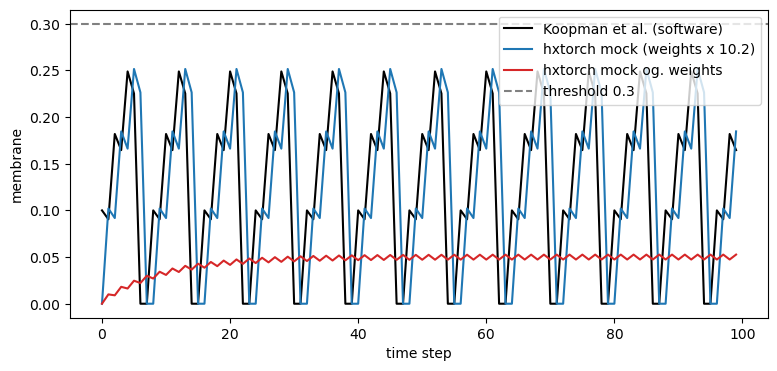

In [6]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import hxtorch
import hxtorch.snn as hxsnn


scale   = 10.2          # weight scale factor: Koopman neuron -> hxtorch neuron
tau_mem = 10e-6     
tau_syn = 1e-6          # synaptic time constant: one time step
dt      = 1e-6          # one time step = 1 microsecond

# Roels neuron
ref = np.load("thesis_import/single_neuron_reference.npz")
x_ref   = ref["x"]          # input: a spike every second step (100 steps)
w       = float(ref["w"])   # input weight (0.1)
thr     = float(ref["thr"]) # threshold (0.3)
mem_ref = ref["mem"]        # membrane trace of Koopman's neuron
spk_ref = ref["spk"]        # spikes of Koopman's neuron

# mock mode on hxtorch 
exp = hxsnn.Experiment(dt=dt, mock=True)

syn = hxsnn.Synapse(in_features=1, out_features=1, experiment=exp)
syn.weight.data.fill_(w * scale)          # the single weight

lif = hxsnn.LIF(size=1, experiment=exp, tau_mem=tau_mem, tau_syn=tau_syn,
                leak=hxsnn.MixedHXModelParameter(0., 80),
                reset=hxsnn.MixedHXModelParameter(0., 80),
                threshold=hxsnn.MixedHXModelParameter(thr, 125))

# same input as Koopman's neuron, shaped (time, batch, neuron) = (100, 1, 1)
inputs = torch.tensor(x_ref, dtype=torch.float32).reshape(100, 1, 1)

z = lif(syn(hxsnn.LIFObservables(spikes=inputs)))
hxsnn.run(exp, 100)

mem_hx = z.membrane_cadc.detach().numpy().reshape(100)   # membrane trace
spk_hx = z.spikes.detach().numpy().reshape(100)          # spikes (0 or 1 per step)

# mock mode original weights ---------------------------
exp1 = hxsnn.Experiment(dt=dt, mock=True)

syn1 = hxsnn.Synapse(in_features=1, out_features=1, experiment=exp1)
syn1.weight.data.fill_(w)          # the single weight

lif1 = hxsnn.LIF(size=1, experiment=exp1, tau_mem=tau_mem, tau_syn=tau_syn,
                leak=hxsnn.MixedHXModelParameter(0., 80),
                reset=hxsnn.MixedHXModelParameter(0., 80),
                threshold=hxsnn.MixedHXModelParameter(thr, 125))


z1 = lif1(syn1(hxsnn.LIFObservables(spikes=inputs)))
hxsnn.run(exp1, 100)

mem_hx = z.membrane_cadc.detach().numpy().reshape(100)   # membrane trace
spk_hx = z.spikes.detach().numpy().reshape(100)          # spikes (0 or 1 per step)

mem_hx1 = z1.membrane_cadc.detach().numpy().reshape(100)   # membrane trace
spk_hx1 = z1.spikes.detach().numpy().reshape(100)          # spikes (0 or 1 per step)

print("Koopman spikes:", np.flatnonzero(spk_ref))
print("hxtorch spikes:", np.flatnonzero(spk_hx))
print("hxtorch spikes og:", np.flatnonzero(spk_hx1))

plt.figure(figsize=(9, 4))
plt.plot(mem_ref, color="black", label="Koopman et al. (software)")
plt.plot(mem_hx, color="tab:blue", label=f"hxtorch mock (weights x {scale})")
plt.plot(mem_hx1, color="tab:red", label=f"hxtorch mock og. weights")
# original hxtorch neuron
plt.axhline(thr, color="gray", linestyle="--", label="threshold 0.3")
plt.xlabel("time step")
plt.ylabel("membrane")
plt.legend()
plt.savefig("thesis_import/single_neuron_comparison.png")
plt.show()

#### dump from thesis main file (later)